In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_sac_actuated")

In [ ]:
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True, remove_trials=False)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(
        f"  {param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [3]:
from src.models.mtf_sac_model import MTF_SAC_Model
from src.main import init_dataset
from src.environments.pendulum import integrate_controlled_pendulum, Hamiltonian, transform_to_cartesian, check_for_stabilization, sample_init_cond

GOAL_STATE = tc.tensor([0.0, -1.0, 0.0, -1.0, 0.0, 0.0])
T_DYNAMICS = 400
T_CONTROL = 400
CONTROL_STATUS = np.concatenate(2*([0]*T_DYNAMICS, [1]*T_CONTROL))
RUN = "001"
DEVICE = tc.device("cpu")
PENDULUM_PARAMETERS = np.load(DATA_DIR + "/multi_task_double_pendulum/default/params.npy", allow_pickle=True)
DATASET = init_dataset(json.load(open(RESULTS_DIR + '/pendulum_different/params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=8p60_adsr=210p04_ac=4p61_seqlen=30/001/config.json')), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX = {DATASET.evaluator_test_samples[i].measurement_index: DATASET.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET.evaluator_test_samples)-1, -1, -1)}


Sequence length set to 30.


In [ ]:
trial_folder_name = "params_subjects=16_q_hid1=93_pol_hid1=73_steps=29_init_temp=1p65_polyak_tau=0p00_noise=0p18_q_lr=0p03_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=16p22_apolicy=116p45_q_hid2=85_pol_hid2=66"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))
stabilized_true = np.zeros((len(runs), 16, 10))
stabilized_model = np.zeros((len(runs), 16, 10))
rewards_true = np.zeros((len(runs), 16, 10))
rewards_model = np.zeros((len(runs), 16, 10))

tc.manual_seed(1)
for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    
    parameters = json.load(open(f"{run_path}/config.json"))
    mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
    model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)
    
    for measurement_index in range(16):
        for j in range(10):
            x0 = sample_init_cond()
            observed_trajectory, _, actions = integrate_controlled_pendulum(model, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=500, apply_actions=True, expected=True)
            stabilized_true[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_true[k, measurement_index, j] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()            
            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
                _,
                actions,
                _,
                _,
                _,
                _,
                _) = model.generate_free_trajectory(
                        x0.unsqueeze(0),
                        cumulative_timeseries_index,
                        measurement_index,
                        apply_actions=True,
                        T=500, 
                        expected =True,
                )
            
            stabilized_model[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_model[k, measurement_index, j] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()            

RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_sac_actuated_independent")
trial_folder_name = "params_subjects=16_q_hid1=61_pol_hid1=78_steps=26_init_temp=-4p17_polyak_tau=0p00_noise=0p17_q_lr=0p01_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=48p36_apolicy=52p99_q_hid2=54_pol_hid2=72"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))
stabilized_true_separate = np.zeros((len(runs), 16, 10))
stabilized_model_separate = np.zeros((len(runs), 16, 10))
rewards_true_separate = np.zeros((len(runs), 16, 10))
rewards_model_separate = np.zeros((len(runs), 16, 10))

tc.manual_seed(1)
for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)

    model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)
    
    for measurement_index in range(16):
        for j in range(10):
            x0 = sample_init_cond()
            observed_trajectory, _, actions = integrate_controlled_pendulum(model, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=500, apply_actions=True, expected=True)
            stabilized_true_separate[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_true_separate[k, measurement_index, j] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()            
            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
                _,
                actions,
                _,
                _,
                _,
                _,
                _) = model.generate_free_trajectory(
                        x0.unsqueeze(0),
                        cumulative_timeseries_index,
                        measurement_index,
                        apply_actions=True,
                        T=500, 
                        expected =True,
                )
            
            stabilized_model_separate[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_model_separate[k, measurement_index, j] = model.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

In [6]:
print(np.median(rewards_true.mean(axis=2), axis = 1).mean(), np.median(rewards_true.mean(axis=2), axis = 1).std())
print(np.median(rewards_true_separate.mean(axis=2), axis = 1).mean(), np.median(rewards_true_separate.mean(axis=2), axis = 1).std())
print(np.median(rewards_model.mean(axis=2), axis = 1).mean(), np.median(rewards_model.mean(axis=2), axis = 1).std())
print(np.median(rewards_model_separate.mean(axis=2), axis = 1).mean(), np.median(rewards_model_separate.mean(axis=2), axis = 1).std())

-9.802383959136511 2.4662548122782697
-16.823122203350067 7.780043593229563
-47.046878907555026 10.103699702539759
-51.00272705338218 18.47145052867129


In [7]:
print(np.median(stabilized_true.mean(axis=2), axis = 1).mean(), np.median(stabilized_true.mean(axis=2), axis = 1).std())
print(np.median(stabilized_true_separate.mean(axis=2), axis = 1).mean(), np.median(stabilized_true_separate.mean(axis=2), axis = 1).std())
print(np.median(stabilized_model.mean(axis=2), axis = 1).mean(), np.median(stabilized_model.mean(axis=2), axis = 1).std())
print(np.median(stabilized_model_separate.mean(axis=2), axis = 1).mean(), np.median(stabilized_model_separate.mean(axis=2), axis = 1).std())

0.5026315789473684 0.4791642077097772
0.22727272727272727 0.39101478486557395
0.17105263157894737 0.2759270448361707
0.17727272727272728 0.18873217720024268


## Analysis

In [8]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_sac_actuated")
trial_folder_name = "params_subjects=16_q_hid1=93_pol_hid1=73_steps=29_init_temp=1p65_polyak_tau=0p00_noise=0p18_q_lr=0p03_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=16p22_apolicy=116p45_q_hid2=85_pol_hid2=66"
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
parameters = json.load(open(f"{run_path}/config.json"))
mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
model = MTF_SAC_Model(DATASET, model_path=run_path, device=DEVICE)

subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()

Encoder model parameters: 11200
DSR model parameters: 45856
Decoder model parameters: 0
SAC model parameters: 202676


In [9]:
true_system = True

observed_trajectory_all = []
latent_trajectory_all = []
actions_all = []
q_value_all = []
value_function_all = []
time_series_per_measurement = 4

tc.manual_seed(1)
for measurement_index in range(16):
    theta1 = tc.rand(1) * 2 * np.pi - np.pi
    theta2 = tc.rand(1) * 2 * np.pi - np.pi
    omega1 = float((tc.rand(1) * 2 - 1))
    omega2 = float((tc.rand(1) * 2 - 1))
    x0 = tc.tensor([np.sin(theta1), np.cos(theta1), np.sin(theta2), np.cos(theta2), omega1, omega2])
    observed_trajectory_cat = []
    latent_trajectory_cat = []
    actions_cat = []
    apply_actions = False

    for _ in range(4):
        T = T_DYNAMICS if not apply_actions else T_CONTROL
        if true_system:
            observed_trajectory, latent_trajectory, actions = integrate_controlled_pendulum(model, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], T=T, apply_actions=apply_actions, expected=True)
        else:
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            (observed_trajectory,
            latent_trajectory,
            actions,
            _,
            _,
            _,
            _,
            _) = model.generate_free_trajectory(
                    tc.stack([x0]*T, dim=0).float(), 
                    cumulative_timeseries_index,
                    measurement_index,
                    apply_actions=apply_actions,
                    T=T, 
                    expected =True,
            )
        apply_actions = not apply_actions
        x0 = observed_trajectory[0, -1]
        actions_cat.append(actions[0])
        observed_trajectory_cat.append(observed_trajectory[0, :-1])
        latent_trajectory_cat.append(latent_trajectory[0, :-1])
        
    observed_trajectory_all.append(tc.cat(observed_trajectory_cat, dim=0))
    actions_all.append(tc.cat(actions_cat, dim=0))
    latent_trajectory_all.append(tc.cat(latent_trajectory_cat, dim=0))
    
    
    value_function = compute_value_function(model, latent_trajectory_all[-1], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index], n_samples=2)
    value_function_all.append(value_function)
    
    q_value = compute_q(model, latent_trajectory_all[-1], actions_all[-1], MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index])
    q_value_all.append(q_value)

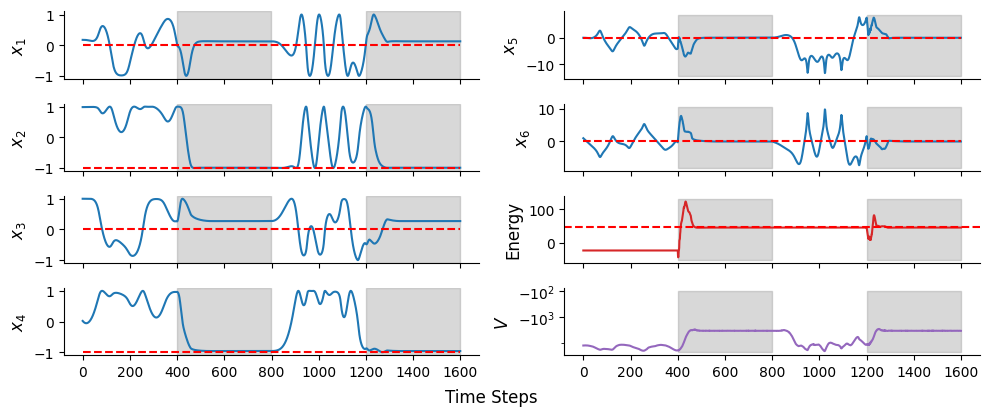

In [10]:
assert true_system == True
measurement_index = 15

fig, axs = plt.subplots(4, 2, figsize=(10, 4), sharex=True)
for i in range(6):
    ax = axs[i%4 , i//4]
    ax.plot(observed_trajectory_all[measurement_index][:, i].detach())
    ax.set_ylabel(f"$x_{i+1}$", fontsize=FONT_SIZE)
    ax.hlines(y=GOAL_STATE[i].item(), color='r', xmin=0, xmax=observed_trajectory_all[0][:].shape[0], linestyles='dashed')
    if i < 4:
        ax.set_ylim(-1.1, 1.1)

energy = Hamiltonian(observed_trajectory_all[measurement_index].detach(), params=PENDULUM_PARAMETERS[measurement_index])[0]
goal_energy = Hamiltonian(GOAL_STATE, params=PENDULUM_PARAMETERS[measurement_index])[0]

axs[2, 1].plot(energy,  c='C3')
axs[2, 1].axhline(y=goal_energy, c='r', linestyle='--')
#axs[2, 1].set_yscale('symlog')
#axs[2, 1].set_yticks([-10, 0, 10])
axs[2, 1].set_ylabel(r"Energy", fontsize=FONT_SIZE)

axs[3, 1].plot(value_function_all[measurement_index].detach(), c='C4')
axs[3, 1].set_yscale('symlog')
axs[3, 1].set_yticks([-1000, -100])
axs[3, 1].set_ylabel(r"$V$", fontsize=FONT_SIZE)
    
for ax in axs.flatten():
    ax.fill_between(x=np.arange(len(CONTROL_STATUS[:])), y1=ax.get_ylim()[0], y2=ax.get_ylim()[1], where=(CONTROL_STATUS[:]==1), color='gray', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.text(0.45, -0.02, 'Time Steps', fontsize=FONT_SIZE)
plt.tight_layout()
plt.show()
#save_fig(fig, "sac_pendulum_example_{}".format(measurement_index))

In [11]:
assert true_system == True

for measurement_index in range(16):
    print(measurement_index)
    print(check_for_stabilization(observed_trajectory_all[measurement_index], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100))
    fig, axs = plt.subplots(4, 2, figsize=(12, 4), sharex=True)
    for i in range(6):
        ax = axs[i%4 , i//4]
        ax.plot(observed_trajectory_all[measurement_index][:, i].detach())
        ax.set_ylabel(f"$x_{i+1}$", fontsize=FONT_SIZE)
        ax.hlines(y=GOAL_STATE[i].item(), color='r', xmin=0, xmax=observed_trajectory_all[0][:].shape[0], linestyles='dashed')
        if i < 4:
            ax.set_ylim(-1.1, 1.1)

    energy = Hamiltonian(observed_trajectory_all[measurement_index].detach(), params=PENDULUM_PARAMETERS[measurement_index])[0]
    goal_energy = Hamiltonian(GOAL_STATE, params=PENDULUM_PARAMETERS[measurement_index])[0]
    
    axs[2, 1].plot(energy,  c='C3')
    axs[2, 1].axhline(y=goal_energy, c='r', linestyle='--')
    #axs[2, 1].set_yscale('symlog')
    #axs[2, 1].set_yticks([-10, 0, 10])
    axs[2, 1].set_ylabel(r"Energy", fontsize=FONT_SIZE)
    
    axs[3, 1].plot(value_function_all[measurement_index].detach(), c='C4')
    axs[3, 1].set_yscale('symlog')
    axs[3, 1].set_yticks([-1000, -10, 0, 10])
    axs[3, 1].set_ylabel(r"$V$", fontsize=FONT_SIZE)
        
    for ax in axs.flatten():
        ax.fill_between(x=np.arange(len(CONTROL_STATUS[:])), y1=ax.get_ylim()[0], y2=ax.get_ylim()[1], where=(CONTROL_STATUS[:]==1), color='gray', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    fig.text(0.45, -0.02, 'Time Steps', fontsize=FONT_SIZE)
    plt.tight_layout()
    plt.show()

In [ ]:
align_pdf_figures([
    FIG_DIR + "/pendulum_subject_vectors_pca_width_53_height_30.pdf",
    FIG_DIR + "/sac_pendulum_example_15_width_97_height_39.pdf",
],
    output_pdf="combined_figures3.pdf",
    rows=1,
)

PosixPath('combined_figures3.pdf')

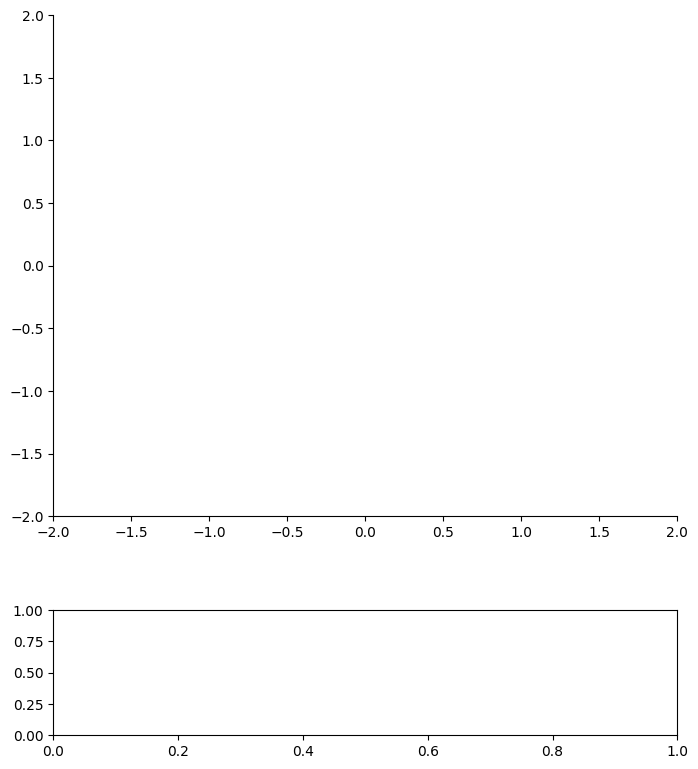

In [ ]:
# integrate
from matplotlib.animation import FuncAnimation

measurement_index = 1
trajectories_test_cartesian = transform_to_cartesian(observed_trajectory_all[measurement_index][:2000].detach().numpy(), parameters = PENDULUM_PARAMETERS[measurement_index])

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8, 8), height_ratios=[4, 1], sharex=False)
fig.subplots_adjust(left=0.2, right=0.98, top=0.98, bottom=0.08, hspace=0.3)

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
line, = ax.plot([], [], 'o-', lw=2)


def init():
    line.set_data([], [])
    return line,


def update(frame):
    x1 = trajectories_test_cartesian[frame, 0]
    y1 = trajectories_test_cartesian[frame, 1]
    x2 = trajectories_test_cartesian[frame, 2]
    y2 = trajectories_test_cartesian[frame, 3]
    line.set_data([0, x1, x2], [0, y1, y2])

    ax2.clear()
    control_frame = min(frame, len(CONTROL_STATUS) - 1)
    ax2.plot(CONTROL_STATUS[:control_frame + 1], color='blue', linewidth=3)
    ax2.set_ylim(-0.1, 1.1)
    ax2.set_xlim(0, len(CONTROL_STATUS))
    ax2.set_xlabel('Time step', fontsize=12)
    ax2.set_ylabel('Control', fontsize=11, labelpad=10)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.set_yticks([0, 1], labels=['Off', 'On'], fontsize=11)
    return line,


ani = FuncAnimation(
    fig,
    update,
    frames=min(len(trajectories_test_cartesian), len(CONTROL_STATUS)),
    init_func=init,
    blit=False,
)
plt.show()
ani.save("double_pendulum_controlled.mp4", writer="ffmpeg", fps=int(round(1 / 0.01)))

## Fine Tuning

In [12]:
from src.models.mtf_model import MTFModel
from copy import deepcopy

GOAL_STATE = tc.tensor([0.0, -1.0, 0.0, -1.0, 0.0, 0.0])
T_DYNAMICS = 300
T_CONTROL = 500
CONTROL_STATUS = np.concatenate(2*([0]*T_DYNAMICS, [1]*T_CONTROL))
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_different_ft")
RUN = "001"
DEVICE = tc.device("cpu")
DATASET_FT = init_dataset(json.load(open(RESULTS_DIR + f"{'/pendulum_different_ft/params_dsr_lr=0p00_lr_gamma=1p00_gtf=0p00_gtf_gamma=0p99_aent=1p28_adsr=177p18_ac=0p17_seqlen=32/001'}/config.json")), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX_FT = {DATASET_FT.evaluator_test_samples[i].measurement_index: DATASET_FT.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET_FT.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 32.


In [14]:
# load test set
full_ft = tc.as_tensor(np.load(DATA_DIR + "/multi_task_double_pendulum/default/full_ft.npy", allow_pickle=True))

trial_folder_name = "params_dsr_lr=0p00_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=1p33_adsr=242p39_ac=0p01_seqlen=42"
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)

world_model_parameters_ft = json.load(open(f"{run_path}/config.json"))
world_model_ft = MTFModel(DATASET_FT, model_path=run_path, device=DEVICE)
# copy model 
model_ft = deepcopy(model.to(DEVICE))

model_ft.dsr_sac_model.latent_step_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.dsr_sac_model.policy_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.dsr_sac_model.q1_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors 
model_ft.dsr_sac_model.q2_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
model_ft.encoder_model.encoder_params.subjects = world_model_ft.encoder_model.encoder_params.subjects
model_ft.dsr_sac_model.to(DEVICE)
pass

Encoder model parameters: 11200
DSR model parameters: 45856
Decoder model parameters: 0


In [ ]:
true_system = True

observed_trajectory_all_ft = []
latent_trajectory_all_ft = []
actions_all_ft = []
q_value_all_ft = []
value_function_all_ft = []
time_series_per_measurement = 4

tc.manual_seed(1)
for measurement_index in range(16):
    x0 = sample_init_cond()
    observed_trajectory_cat = []
    latent_trajectory_cat = []
    actions_cat = []
    apply_actions = False

    for _ in range(4):
        T = T_DYNAMICS if not apply_actions else T_CONTROL
        if true_system:
            observed_trajectory, latent_trajectory, actions = integrate_controlled_pendulum(model_ft, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=T, apply_actions=apply_actions, expected=True, fine_tuning_params=True)
        else:
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
            latent_trajectory,
            actions,
            _,
            _,
            _,
            _,
            _) = model_ft.generate_free_trajectory(
                    tc.stack([x0]*T, dim=0).float(), 
                    cumulative_timeseries_index,
                    measurement_index,
                    apply_actions=apply_actions,
                    T=T, 
                    expected =True,
            )
        apply_actions = not apply_actions
        x0 = observed_trajectory[0, -1]
        actions_cat.append(actions[0])
        observed_trajectory_cat.append(observed_trajectory[0, :-1])
        latent_trajectory_cat.append(latent_trajectory[0, :-1])
        
    observed_trajectory_all_ft.append(tc.cat(observed_trajectory_cat, dim=0))
    actions_all_ft.append(tc.cat(actions_cat, dim=0))
    latent_trajectory_all_ft.append(tc.cat(latent_trajectory_cat, dim=0))
    
    
    value_function = compute_value_function(model_ft, latent_trajectory_all_ft[-1], measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], n_samples=2)
    value_function_all_ft.append(value_function)
    
    q_value = compute_q(model_ft, latent_trajectory_all_ft[-1], actions_all_ft[-1], MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index])
    q_value_all_ft.append(q_value)

False


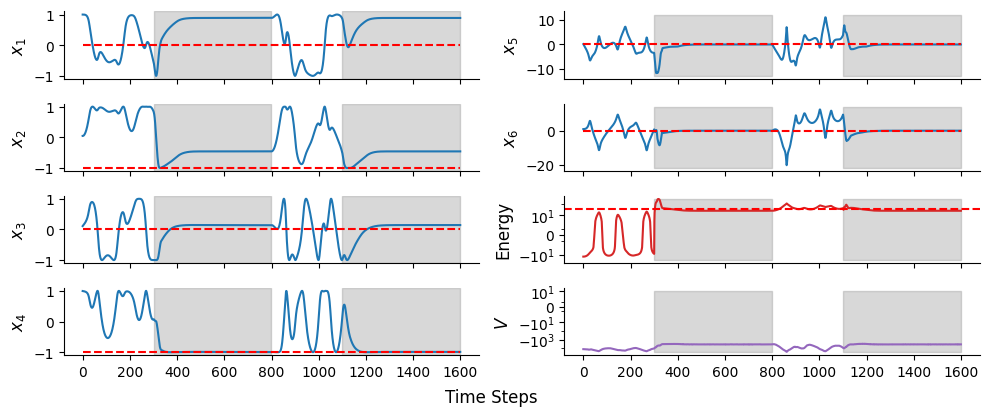

In [16]:
assert true_system == True
measurement_index = 14

print(check_for_stabilization(observed_trajectory_all_ft[measurement_index], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100))
fig, axs = plt.subplots(4, 2, figsize=(10, 4), sharex=True)
for i in range(6):
    ax = axs[i%4 , i//4]
    ax.plot(observed_trajectory_all_ft[measurement_index][:, i].cpu().detach())
    ax.set_ylabel(f"$x_{i+1}$", fontsize=FONT_SIZE)
    ax.hlines(y=GOAL_STATE[i].item(), color='r', xmin=0, xmax=observed_trajectory_all_ft[0][:].shape[0], linestyles='dashed')
    if i < 4:
        ax.set_ylim(-1.1, 1.1)

energy = Hamiltonian(observed_trajectory_all_ft[measurement_index].detach(), params=PENDULUM_PARAMETERS[measurement_index])[0]
goal_energy = Hamiltonian(GOAL_STATE, params=PENDULUM_PARAMETERS[measurement_index])[0]

axs[2, 1].plot(energy.cpu(),  c='C3')
axs[2, 1].axhline(y=goal_energy, c='r', linestyle='--')
axs[2, 1].set_yscale('symlog')
axs[2, 1].set_yticks([-10, 0, 10])
axs[2, 1].set_ylabel(r"Energy", fontsize=FONT_SIZE)

axs[3, 1].plot(value_function_all_ft[measurement_index].cpu().detach(), c='C4')
axs[3, 1].set_yscale('symlog')
axs[3, 1].set_yticks([-1000, -10, 0, 10])
axs[3, 1].set_ylabel(r"$V$", fontsize=FONT_SIZE)
    
for ax in axs.flatten():
    ax.fill_between(x=np.arange(len(CONTROL_STATUS[:])), y1=ax.get_ylim()[0], y2=ax.get_ylim()[1], where=(CONTROL_STATUS[:]==1), color='gray', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.text(0.45, -0.02, 'Time Steps', fontsize=FONT_SIZE)
plt.tight_layout()
plt.show()
#save_fig(fig, "sac_pendulum_example_ft{}".format(measurement_index))

In [ ]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_sac_actuated")
trial_folder_name = "params_subjects=16_q_hid1=93_pol_hid1=73_steps=29_init_temp=1p65_polyak_tau=0p00_noise=0p18_q_lr=0p03_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=16p22_apolicy=116p45_q_hid2=85_pol_hid2=66"
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))[:10]
stabilized_true_ft = np.zeros((len(runs), 16, 10))
stabilized_model_ft = np.zeros((len(runs), 16, 10))
rewards_true_ft = np.zeros((len(runs), 16, 10))
rewards_model_ft = np.zeros((len(runs), 16, 10))
stabilized_true_ft_old_subjects = np.zeros((len(runs), 16, 10))
stabilized_model_ft_old_subjects = np.zeros((len(runs), 16, 10))
rewards_true_ft_old_subjects = np.zeros((len(runs), 16, 10))
rewards_model_ft_old_subjects = np.zeros((len(runs), 16, 10))

for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    model_ft = MTF_SAC_Model(DATASET_FT, model_path=run_path, device=DEVICE)
    
    model_ft.dsr_sac_model.latent_step_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
    model_ft.to(DEVICE)

    tc.manual_seed(1)
    for measurement_index in range(16):
        for j in range(10):
            x0 = sample_init_cond().to(DEVICE)
            observed_trajectory, _, actions = integrate_controlled_pendulum(model_ft, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=500, apply_actions=True, expected=True, fine_tuning_params=True)
            stabilized_true_ft_old_subjects[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_true_ft_old_subjects[k, measurement_index, j] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
                _,
                actions,
                _,
                _,
                _,
                _,
                _) = model_ft.generate_free_trajectory(
                        x0.unsqueeze(0),
                        cumulative_timeseries_index,
                        measurement_index,
                        apply_actions=True,
                        T=500, 
                        expected =True,
                )
            
            stabilized_model_ft_old_subjects[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_model_ft_old_subjects[k, measurement_index, j] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()        

    model_ft.dsr_sac_model.policy_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors
    model_ft.dsr_sac_model.q1_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors 
    model_ft.dsr_sac_model.q2_params.subject_vectors = world_model_ft.dsr_model.latent_step_params.subject_vectors

    tc.manual_seed(1)
    for measurement_index in range(16):
        for j in range(10):
            x0 = sample_init_cond().to(DEVICE)
            observed_trajectory, _, actions = integrate_controlled_pendulum(model_ft, x0, measurement_index, MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index], T=500, apply_actions=True, expected=True, fine_tuning_params=True)
            stabilized_true_ft[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_true_ft[k, measurement_index, j] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()            
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
            (observed_trajectory,
                _,
                actions,
                _,
                _,
                _,
                _,
                _) = model_ft.generate_free_trajectory(
                        x0.unsqueeze(0),
                        cumulative_timeseries_index,
                        measurement_index,
                        apply_actions=True,
                        T=500, 
                        expected =True,
                )
            
            stabilized_model_ft[k, measurement_index, j] = check_for_stabilization(observed_trajectory[0], GOAL_STATE, position_tol=5, angle_tol=0.5, velocity_tol=5, final_window=100)
            rewards_model_ft[k, measurement_index, j] = model_ft.reward_function(observed_trajectory[:, 1:], actions, measurement_index).detach().squeeze()[15:].mean()

In [18]:
# t test
test =ttest_rel(np.median(rewards_true_ft.mean(axis=2), axis=1), np.median(rewards_true_ft_old_subjects.mean(axis=2), axis=1))
df = test.df
t_statistic = test.statistic
p_value = test.pvalue
print(f"t-statistic: {t_statistic}, degrees of freedom: {df}, p-value: {p_value}")

t-statistic: -1.427251865340734, degrees of freedom: 9, p-value: 0.18726812357718897


## Baseline

In [ ]:
import numpy as np

for architecture in ["cem_mpc", "td_mpc", "dreamerv3"]:
    for environment in ["world_model_", ""]:
        if architecture == "cem_mpc":
            path =  RESULTS_DIR + f"/baselines/{architecture}/pendulum_{environment}rewards_all.npy"
        elif architecture == "td_mpc":
            path =  RESULTS_DIR + f"/baselines/{architecture}/{architecture}_pendulum_results/{architecture}_pendulum_{environment}rewards_all.npy"
        elif architecture == "dreamerv3":
            path =  RESULTS_DIR + f"/baselines/{architecture}/{architecture}_pendulum_results_very_small/{architecture}_pendulum_{environment}rewards_all.npy"
            
        try:
            rewards_all = np.load(path)
        except FileNotFoundError:
            print(f"File not found: {path}")
            continue
        rewards_all_per_run = np.median(rewards_all.mean(axis=2), axis=1)
        # infer how many entries are non nan
        index = np.where(~np.isnan(rewards_all_per_run))[0][-1] + 1
        print(f"{architecture}_{environment}: {rewards_all_per_run[:index].mean():.3f} ({rewards_all_per_run[:index].std():.4f})")

cem_mpc_world_model_: -15.347 (0.7049)
cem_mpc_: -6.342 (0.5543)
td_mpc_world_model_: -6013.157 (2282.4506)
td_mpc_: -17.111 (3.7761)
dreamerv3_world_model_: -6.395 (0.7763)
dreamerv3_: -5.868 (0.2967)
